# 03 – Amounts and recent account activity
Questions: do laundering payments differ in size? Are the accounts involved more active in the previous hour/day?
Splits used: **train only**.
Methods: within-currency amount percentiles, Mann–Whitney U test with AUC / rank-biserial effect sizes, laundering rate by bucket with 95% Wilson intervals.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "analysis").is_dir())
sys.path.insert(0, str(ROOT))

from src.analysis.data import load_eda_frame
from src.analysis.stats import rate_table, mann_whitney_test

pd.set_option("display.max_columns", 30)
train = load_eda_frame()
overall_rate = 100 * train["is_laundering"].mean()

COUNTS = [
    "sender_txn_count_1h", "sender_txn_count_24h", "sender_unique_receivers_24h",
    "receiver_txn_count_1h", "receiver_txn_count_24h", "receiver_unique_senders_24h",
]
print(f"Train rows: {len(train):,}   overall laundering rate: {overall_rate:.4f}%")

Train rows: 3,046,861   overall laundering rate: 0.0754%


In [2]:
# Percentile of each amount within its own currency: 0.9 = bigger than 90% of payments in that currency.
train["amount_pct_in_currency"] = (
    train.groupby("payment_currency", observed=True)["log_amount_paid"].rank(pct=True)
)
train.groupby("is_laundering")["amount_pct_in_currency"].median()

is_laundering
0    0.499748
1    0.710055
Name: amount_pct_in_currency, dtype: float64

In [3]:
def plot_rate_by_bucket(table, title, xlabel):
    """Laundering rate per ordered bucket (left to right), with 95% CI whiskers
    and a dashed line at the overall train rate."""
    fig, ax = plt.subplots(figsize=(9, 4))
    x = table.index.astype(str)
    ax.bar(x, table["rate_%"], color="#4C72B0",
           yerr=[table["rate_%"] - table["ci_low_%"], table["ci_high_%"] - table["rate_%"]], capsize=3)
    ax.axhline(overall_rate, linestyle="--", color="grey", label=f"overall {overall_rate:.3f}%")
    for i, n in enumerate(table["transactions"]):
        ax.annotate(f"n={n:,}", (i, 0), textcoords="offset points", xytext=(0, 3),
                    ha="center", fontsize=7, color="white")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Laundering rate (%) with 95% CI")
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    plt.show()

,transactions,laundering,rate_%,ci_low_%,ci_high_%,share_of_laundering_%,lift
amount_decile,,,,,,,
D1,304687,13,0.0043,0.0025,0.0073,0.5660,0.0566
D2,304688,42,0.0138,0.0102,0.0186,1.8285,0.1828
D3,304690,84,0.0276,0.0223,0.0341,3.6569,0.3657
D4,304680,102,0.0335,0.0276,0.0406,4.4406,0.4441
D5,304688,129,0.0423,0.0356,0.0503,5.6160,0.5616
D6,304684,271,0.0889,0.0790,0.1002,11.7980,1.1798
D7,304686,435,0.1428,0.1300,0.1568,18.9377,1.8938
D8,304686,578,0.1897,0.1749,0.2058,25.1633,2.5163
D9,304686,572,0.1877,0.1730,0.2037,24.9020,2.4902


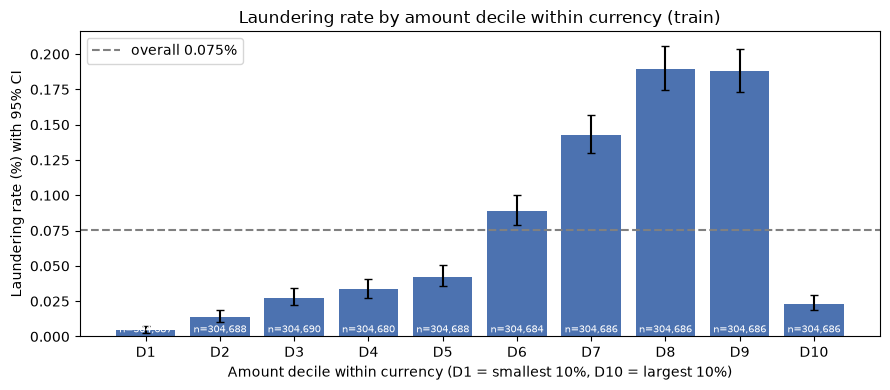

In [4]:
train["amount_decile"] = pd.qcut(
    train["amount_pct_in_currency"], 10, labels=[f"D{i}" for i in range(1, 11)]
)
amount_deciles = rate_table(train, "amount_decile").sort_index()
display(amount_deciles)
plot_rate_by_bucket(
    amount_deciles,
    "Laundering rate by amount decile within currency (train)",
    "Amount decile within currency (D1 = smallest 10%, D10 = largest 10%)",
)

In [5]:
mw = pd.DataFrame(
    [mann_whitney_test(train, c) for c in ["log_amount_paid", "amount_pct_in_currency", *COUNTS]]
).set_index("column")
mw.sort_values("auc", ascending=False)

,median_laundering,median_legitimate,mean_laundering,mean_legitimate,p_value,auc,rank_biserial
column,,,,,,,
amount_pct_in_currency,0.710055,0.499748,0.67,0.50,1.034656e-175,0.6703,0.3406
log_amount_paid,8.849761,7.331014,8.93,7.46,1.266317e-133,0.6482,0.2965
receiver_unique_senders_24h,1.000000,1.000000,1.88,1.40,9.870492e-03,0.5147,0.0294
receiver_txn_count_24h,2.000000,2.000000,2.61,2.46,1.155419e-02,0.4850,-0.0300
sender_unique_receivers_24h,1.000000,2.000000,639.48,320.23,1.586422e-40,0.4212,-0.1575
receiver_txn_count_1h,0.000000,0.000000,0.90,0.80,7.715750e-56,0.4151,-0.1698
sender_txn_count_24h,1.000000,3.000000,1452.15,729.62,2.130891e-49,0.4118,-0.1765
sender_txn_count_1h,0.000000,0.000000,74.34,37.69,2.002618e-84,0.3922,-0.2157


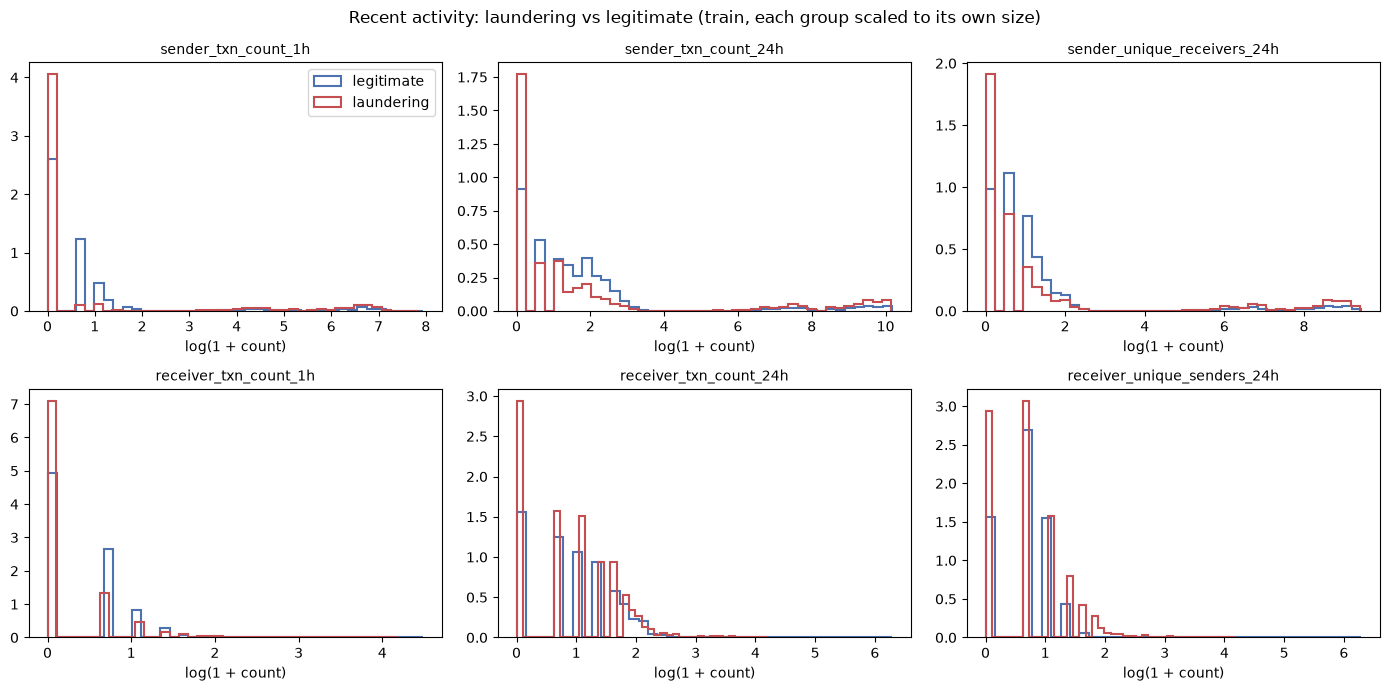

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, COUNTS):
    for label, name, colour in [(0, "legitimate", "#4C72B0"), (1, "laundering", "#C44E52")]:
        values = np.log1p(train.loc[train["is_laundering"] == label, col])
        ax.hist(values, bins=40, density=True, histtype="step", linewidth=1.5, color=colour, label=name)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("log(1 + count)")
axes.flat[0].legend()
fig.suptitle("Recent activity: laundering vs legitimate (train, each group scaled to its own size)")
fig.tight_layout()
plt.show()

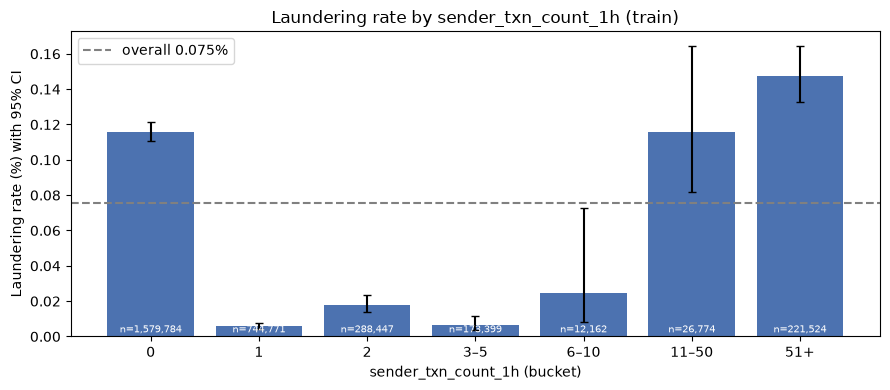

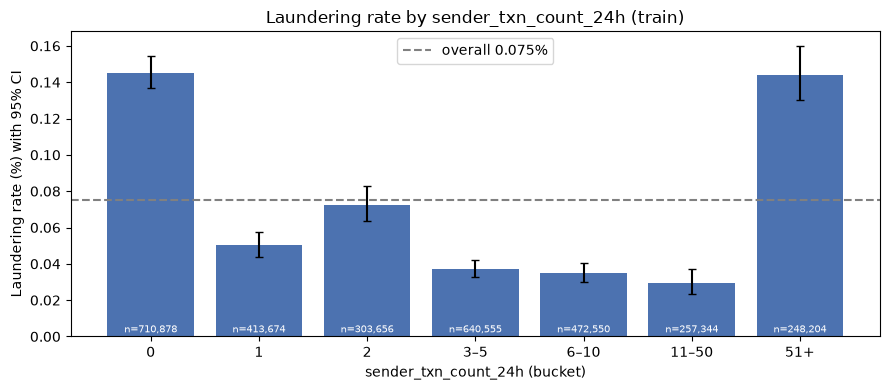

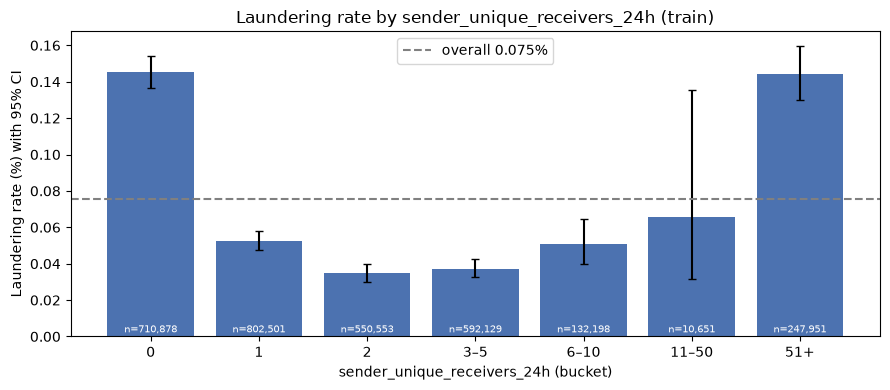

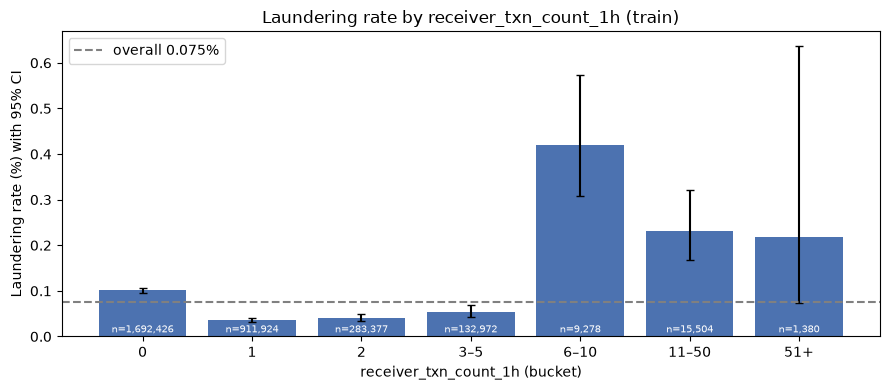

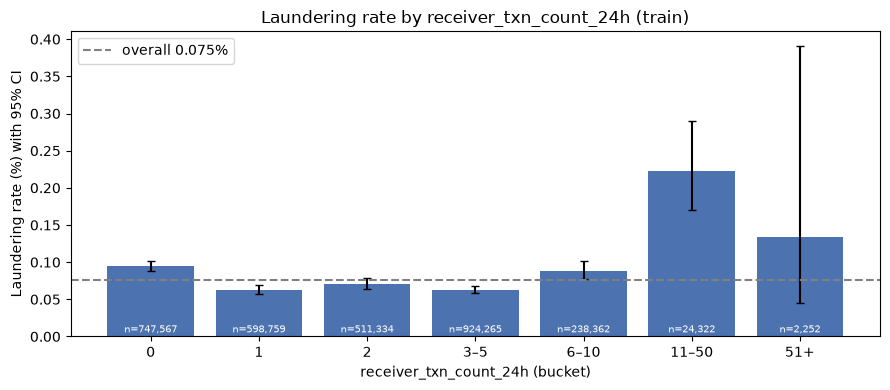

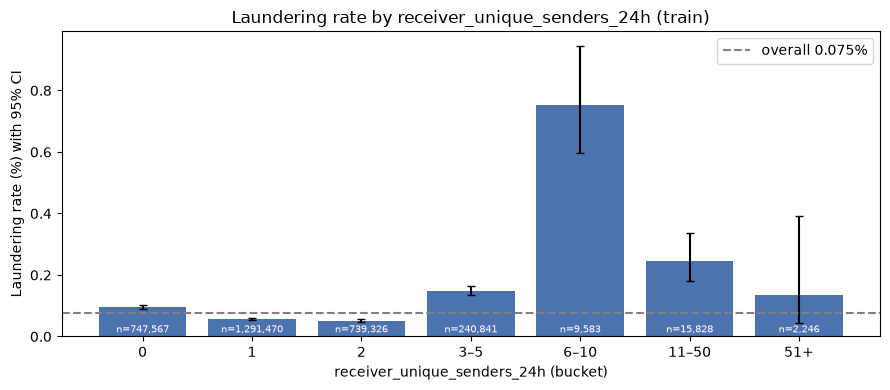

In [7]:
BINS = [-0.5, 0.5, 1.5, 2.5, 5.5, 10.5, 50.5, np.inf]
LABELS = ["0", "1", "2", "3–5", "6–10", "11–50", "51+"]

for col in COUNTS:
    buckets = pd.cut(train[col], bins=BINS, labels=LABELS)
    table = rate_table(train.assign(bucket=buckets), "bucket").sort_index()
    plot_rate_by_bucket(table, f"Laundering rate by {col} (train)", f"{col} (bucket)")

## What I found (train only)
- **Amount is the strongest numeric signal, with an inverted-U shape.** Using each payment's percentile within its own currency (to make currencies comparable), the laundering rate rises from 0.004% in the smallest decile to about 0.19% in deciles 8–9 (2.5× the average), then falls to 0.023% in the largest decile. Deciles 6–9 contain 81% of laundering. Mann–Whitney AUC = 0.67 (rank-biserial 0.34, p < 0.001).
- **Ranking amounts within currency improves on raw amounts** (AUC 0.670 vs 0.648), supporting the within-currency comparison.
- **Sender activity shows a U-shape.** Senders with no payments in the previous 24h, and very busy senders (51+), both launder at about 0.145% (≈2× average), while moderately active senders are below average.
- **Medians and means disagree for sender counts** (24h count: laundering median 1 vs 3, but mean 1,452 vs 730), because laundering comes from both quiet accounts and a few very large hub accounts. Rank-based tests and bucket charts are therefore used instead of means.
- **Receivers paid by many different senders are high-risk ("fan-in").** Receivers with 6–10 distinct senders in the previous 24h launder at 0.75% (10× average), though this group is small (n ≈ 9,600) and the interval is wide.
- **Single-number effect sizes understate non-linear patterns.** The count features have AUCs of only 0.39–0.51, yet the bucket charts show strong effects at both ends. Tree models can capture these U-shapes; logistic regression cannot without binning.
- **Warm-up check:** notebook 04 shows the "no sender history" effect is real. After the first 24 hours, senders with no history launder at 0.34%, about 5.7× senders with history.